# Session 4 - Model Data Comparisons

Revised September 22, 2026 by Sage Lichtenwalner

In this research scenario we will compare CTD data from the [OOI Coastal Pioneer MAB: Southern Profiler Mooring](https://oceanobservatories.org/site/cp13sopm/) with model data from ROMS Doppio, as described in [López, Wilkin, and Levin 2020](https://gmd.copernicus.org/articles/13/3709/2020/).  We will focus on August 2025, when [Hurricane Erin](https://en.wikipedia.org/wiki/Hurricane_Erin_(2025)) passed just offshore of the MAB array.

## Learning Objectives
1. Demonstrate how to compare model and observational (in situ) datasets.
2. Investigate the bottlenecks and strategies for accessing and processing large datasets.
3. Demonstrate how to use xarray and Thredds to access model datasets.

This notebook will also demonstrate how to:
1. Load profiler data directly from the OOI JupyterHub.  (OOI Erddap is also an option for quick views.)
2. Inspect a large remote ROMS dataset without loading it in full.
3. Locate a candidate ROMS grid point near an observing site.
4. Convert ROMS vertical coordinates to physical depth for plotting.
5. Explore how to compare ROMS Doppio model data with observational data from the OOI.


## Notebook Setup

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
# from erddapy import ERDDAP
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os

## Part A - OOI Profiler Data

### Step 1 - Discover - Find relevant OOI Data

For the first part of this study, we will use wire-following profiler CTD data from [CP13SOPM](https://oceanobservatories.org/site/cp13sopm). The profiler measures the water column from approximately 23 to 74 meters, while the mooring site is in approximately 100 meters of water.

There are several ways we could explore and [access the OOI dataset](https://oceanobservatories.org/data-access/) to find data of interest
1. Browse the Data Explorer.  For [example](https://dataexplorer.oceanobservatories.org/#ooi/array/CP1/parameter/7/data?time_filter_active=true&platform_id=profiling-assets&instrument_type_id=CTD), we can use the search inteface to find CTDs in the Mid Atlantic Bight that have data for the time period we might be interested in.
2. Search the [OOI Data Explorer Erddap catalog](https://erddap.dataexplorer.oceanobservatories.org/erddap/index.html).  We could use the web interface or the Erddap API to find relevant data.
3. Or we can access the pre-processed data files directly on the JupyterHub server, which is what we will do here

*Note, the current Erddap dataset is designed to provide quickplots to the Data Explorer interface, so the data is not "research quality."  Therefore, while this is a good source for finding data, it is best to use data from the [Gold Copy Thredds Server](https://thredds.dataexplorer.oceanobservatories.org/thredds/catalog/ooigoldcopy/public/catalog.html) or to access the same files directly in JupyterHub.*


In [2]:
# Let's locate the CTD data directories for this mooring
import glob
instrument_dir = '/home/jovyan/ooi/kdata'
ctd_directories = sorted(glob.glob(f"{instrument_dir}/CP13SOPM*CTD*"))
ctd_directories

['/home/jovyan/ooi/kdata/CP13SOPM-SBI01-02-CTDMOS011-recovered_host-ctdmo_ghqr_imodem_instrument_recovered',
 '/home/jovyan/ooi/kdata/CP13SOPM-SBI01-02-CTDMOS011-recovered_host-ctdmo_ghqr_imodem_metadata_recovered',
 '/home/jovyan/ooi/kdata/CP13SOPM-SBI01-02-CTDMOS011-recovered_inst-ctdmo_ghqr_instrument_recovered',
 '/home/jovyan/ooi/kdata/CP13SOPM-SBI01-02-CTDMOS011-telemetered-ctdmo_ghqr_imodem_instrument',
 '/home/jovyan/ooi/kdata/CP13SOPM-SBI01-02-CTDMOS011-telemetered-ctdmo_ghqr_imodem_metadata',
 '/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered',
 '/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_metadata_recovered',
 '/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-telemetered-ctdpf_ckl_wfp_instrument',
 '/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-telemetered-ctdpf_ckl_wfp_metadata']

In [3]:
# Now let's take a look at the "recovered" datafiles available from the profiling CTD
data_dir = '/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered'
files = sorted(os.listdir(data_dir))
for f in files:
    file = data_dir +"/"+ f
    print(f"{f} : {os.path.getsize(file)/1e6} MB")



CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_annotations.json : 2.3e-05 MB
deployment0001_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered.ncml : 0.001248 MB
deployment0001_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20240416T220013-20250104T212737.nc : 500.420484 MB
deployment0001_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250105T000015-20250205T212757.nc : 56.674649 MB
deployment0001_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250205T212757-20250205T212757.nc : 0.133251 MB
deployment0001_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_aggregate_provenance.json : 0.019668 MB
deployment0002_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered.ncml : 0.001248 MB
deployment0002_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250414T150013-20251

It's always good to look inside your datafiles and the metadata available, so you understand what is or is not included in the file.

NetCDF files are a binary format, so you need special tools like [Panoply](https://www.giss.nasa.gov/tools/panoply/) to look inside them.  

Since we're in python, we can easily open one of the NetCDF files using Xarray to browse the variables and metadata attributes available.

In [4]:
ds = xr.open_dataset(data_dir + '/deployment0002_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250414T150013-20251107T093048.nc')
ds

<xarray.Dataset> Size: 407MB
Dimensions:                                            (obs: 1724290)
Coordinates:
  * obs                                                (obs) int32 7MB 0 ... ...
    lon                                                (obs) float64 14MB ...
    lat                                                (obs) float64 14MB ...
    depth                                              (obs) float64 14MB ...
    time                                               (obs) datetime64[ns] 14MB ...
Data variables: (12/24)
    sea_water_pressure                                 (obs) float64 14MB ...
    sea_water_electrical_conductivity_qartod_results   (obs) uint8 2MB ...
    driver_timestamp                                   (obs) datetime64[ns] 14MB ...
    id                                                 (obs) |S36 62MB ...
    conductivity                                       (obs) float64 14MB ...
    temperature                                        (obs) float64 14MB ...
    ...                                                 ...
    sea_water_temperature                              (obs) float64 14MB ...
    sea_water_density                                  (obs) float64 14MB ...
    sea_water_pressure_qartod_results                  (obs) uint8 2MB ...
    sea_water_electrical_conductivity_qartod_executed  (obs) <U1 7MB ...
    sea_water_electrical_conductivity                  (obs) float64 14MB ...
    sea_water_temperature_qartod_executed              (obs) <U1 7MB ...
Attributes: (12/68)
    node:                               WFP01
    comment:                            
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_wfp
    stream:                             ctdpf_ckl_wfp_instrument_recovered
    ...                                 ...
    geospatial_lon_max:                 -74.8564
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1
    geospatial_vertical_units:          meters
    geospatial_vertical_resolution:     0.1
    geospatial_vertical_positive:       down

### Step 2 - Access - Parsing and loading OOI Profiler
Now that we have a list of very large files, we can load them.  In xarray, we can use `open_dataset` to load a single file. If we have Dask installed, we can use `open_mfdataset` on a list of files to load them all together.  Note, to load Netcdf these files, we also have to have the `netcdf4` library installed.

In [5]:
dfiles = sorted(glob.glob(data_dir + "/*.nc"))
# from pprint import pprint
# pprint(dfiles)
dfiles

['/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/deployment0001_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20240416T220013-20250104T212737.nc',
 '/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/deployment0001_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250105T000015-20250205T212757.nc',
 '/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/deployment0001_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250205T212757-20250205T212757.nc',
 '/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered/deployment0002_CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl_wfp_instrument_recovered_20250414T150013-20251107T093048.nc',
 '/home/jovyan/ooi/kdata/CP13SOPM-WFP01-03-CTDPFK000-recovered_wfp-ctdpf_ckl

Now that we have a list of files, we can pre-load all of the files for later use.  

OOI Netcdf files are index using the "obs" dimensions, which is an integer index that restarts for every file.  So we have to override the default `open_mfdataset` behavior to ignore these duplicate indexes.

In [6]:
# Lazy load all of the files for later use
ds_ooi = xr.open_mfdataset(dfiles, combine='nested', concat_dim='obs') 
ds_ooi

<xarray.Dataset> Size: 1GB
Dimensions:                                            (obs: 5280201)
Coordinates:
  * obs                                                (obs) int32 21MB 0 ......
    lon                                                (obs) float64 42MB dask.array<chunksize=(512,), meta=np.ndarray>
    lat                                                (obs) float64 42MB dask.array<chunksize=(512,), meta=np.ndarray>
    depth                                              (obs) float64 42MB dask.array<chunksize=(512,), meta=np.ndarray>
    time                                               (obs) datetime64[ns] 42MB dask.array<chunksize=(512,), meta=np.ndarray>
Data variables: (12/24)
    sea_water_pressure                                 (obs) float64 42MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_electrical_conductivity_qartod_results   (obs) uint8 5MB dask.array<chunksize=(10000,), meta=np.ndarray>
    driver_timestamp                                   (obs) datetime64[ns] 42MB dask.array<chunksize=(10000,), meta=np.ndarray>
    id                                                 (obs) |S36 190MB dask.array<chunksize=(10000,), meta=np.ndarray>
    conductivity                                       (obs) float64 42MB dask.array<chunksize=(10000,), meta=np.ndarray>
    temperature                                        (obs) float64 42MB dask.array<chunksize=(10000,), meta=np.ndarray>
    ...                                                 ...
    sea_water_temperature                              (obs) float64 42MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_density                                  (obs) float64 42MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_pressure_qartod_results                  (obs) uint8 5MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_electrical_conductivity_qartod_executed  (obs) <U1 21MB dask.array<chunksize=(1989490,), meta=np.ndarray>
    sea_water_electrical_conductivity                  (obs) float64 42MB dask.array<chunksize=(10000,), meta=np.ndarray>
    sea_water_temperature_qartod_executed              (obs) <U1 21MB dask.array<chunksize=(1989490,), meta=np.ndarray>
Attributes: (12/68)
    node:                               WFP01
    comment:                            
    publisher_email:                    
    sourceUrl:                          http://oceanobservatories.org/
    collection_method:                  recovered_wfp
    stream:                             ctdpf_ckl_wfp_instrument_recovered
    ...                                 ...
    geospatial_lon_max:                 -74.8539
    geospatial_lon_units:               degrees_east
    geospatial_lon_resolution:          0.1
    geospatial_vertical_units:          meters
    geospatial_vertical_resolution:     0.1
    geospatial_vertical_positive:       down

In [7]:
print('\nDataset summary')
print(f'  Size:    {ds_ooi.nbytes/1e9:,.3f} GB')

print('Temperature summary')
temp_var = ds_ooi['sea_water_temperature']
print(f'  dims:        {temp_var.dims}')
print(f'  shape:       {temp_var.shape}')
print(f'  dtype:       {temp_var.dtype}')
print(f'  n_values:    {temp_var.size:,}')
print(f'  size:        {temp_var.nbytes/1e6:,.1f} MB')
print(f'  attrs:       {temp_var.attrs}')



Dataset summary
  Size:    1.246 GB
Temperature summary
  dims:        ('obs',)
  shape:       (5280201,)
  dtype:       float64
  n_values:    5,280,201
  size:        42.2 MB
  attrs:       {'comment': 'Seawater temperature near the sensor.', 'long_name': 'Seawater Temperature', 'precision': np.int32(4), 'data_product_identifier': 'TEMPWAT_L1', 'standard_name': 'sea_water_temperature', 'units': 'degrees_Celsius', 'ancillary_variables': 'ctdpf_ckl_seawater_temperature_qartod_results ctdpf_ckl_seawater_temperature_qartod_executed temperature', 'alternate_parameter_name': 'ctdpf_ckl_seawater_temperature'}


### Step 3 - Wrangle (restructure, clean, merge, and quality control)
Let's make a quick plot of the temperature.

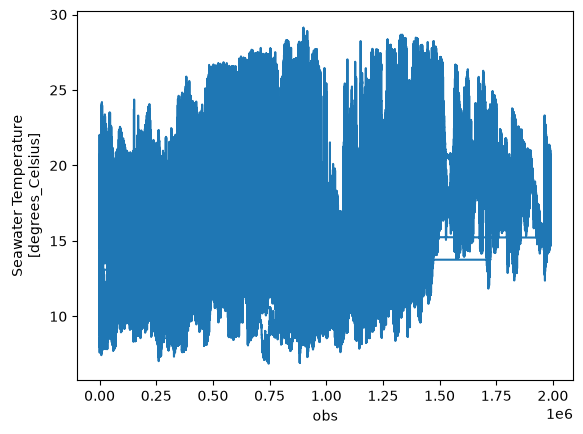

In [8]:
ds_ooi['sea_water_temperature'].plot()

The OOI data files are indexed using the `obs` dimension, which isn't very helpful.  If we swap that for the `time` dimension we can take advantage of xarray's native plotting and other analysis capabilities.


In [9]:
ds_ooi = ds_ooi.swap_dims({'obs': 'time'}) # Swap the primary dimension

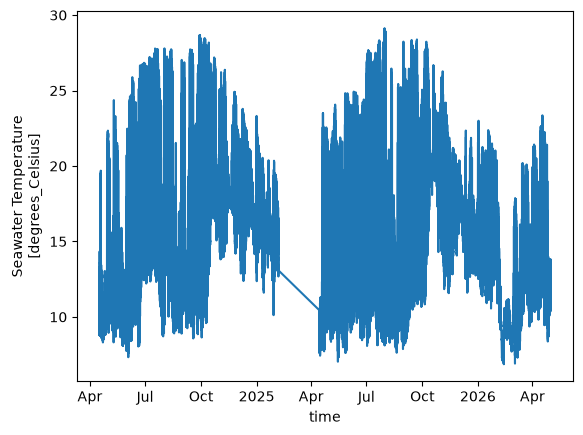

In [10]:
# Let's plot temperature again.
ds_ooi['sea_water_temperature'].plot()

Notice the x-axis now shows actual dates instead of the raw `obs` index, thanks to the `swap_dims` call above.

It's always important to check the quality of the data we're using. 

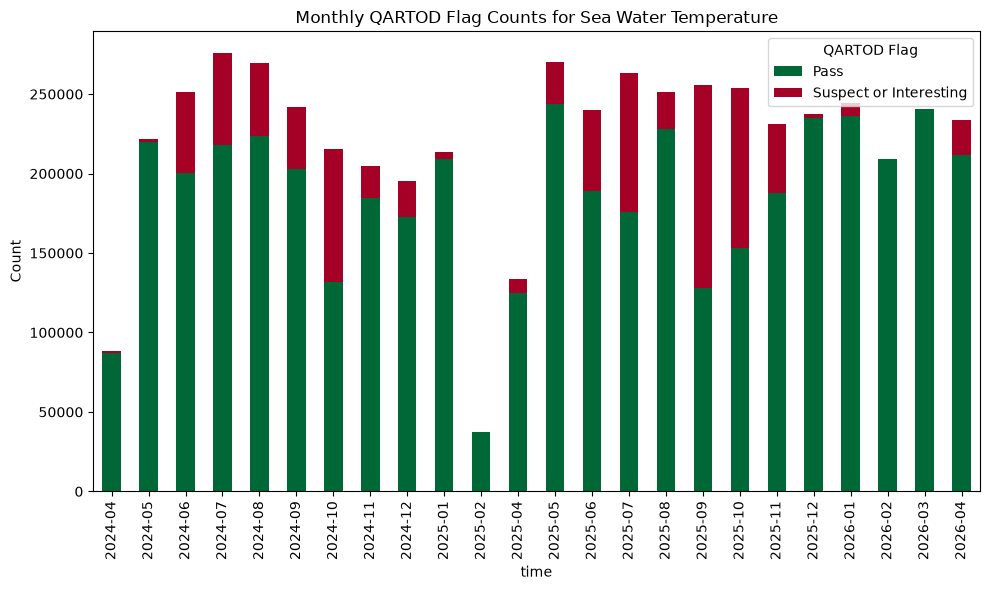

In [11]:
# This is a simple way to look at the QUARTOD flags
# ds_ooi['sea_water_temperature_qartod_executed'].plot(marker='.',linestyle='')

# And here is a more advanced approach
flag_meanings = {1: 'Pass', 2: 'Not Evaluated', 3: 'Suspect or Interesting', 4: 'Fail', 9: 'Missing'}

# QARTOD flags are stored as single-character strings, so cast to int for counting
qartod = ds_ooi['sea_water_temperature_qartod_executed'].compute().to_series().astype(int)

monthly_flag_counts = (
    qartod.groupby([qartod.index.to_period('M'), qartod])
    .size()
    .unstack(fill_value=0)
    .rename(columns=flag_meanings)
)
monthly_flag_counts.index = monthly_flag_counts.index.strftime('%Y-%m')

ax = monthly_flag_counts.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='RdYlGn_r')
# ax.set_xlabel('Month')
ax.set_ylabel('Count')
ax.set_title('Monthly QARTOD Flag Counts for Sea Water Temperature')
ax.legend(title='QARTOD Flag')
plt.tight_layout()
plt.show()

For this dataset, all of the data is flagged 1=good, or 3=suspect, but nothing has been outright flagged bad.  So we should be careful when using the suspect data, but it could still be valid, and might have just tripped the crude outlier checks.

### Step 4 - Reuse - Visualization and Analysis

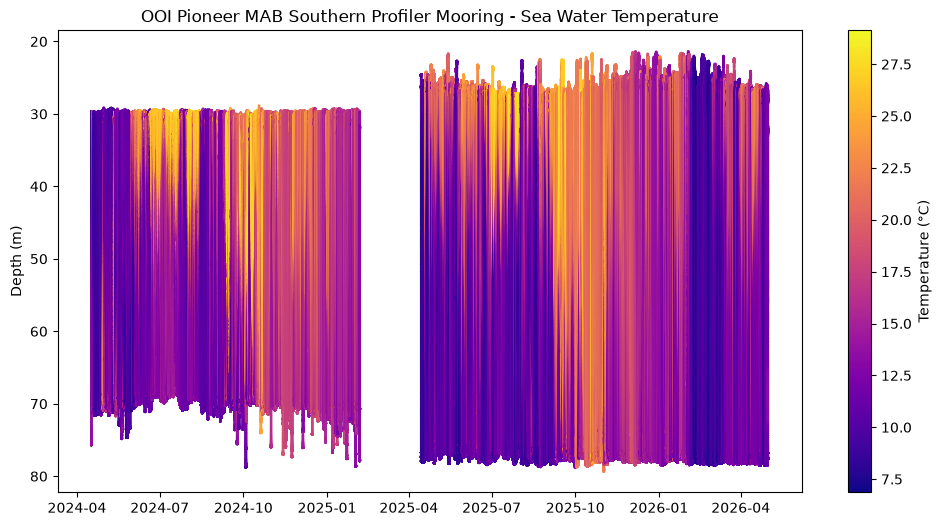

In [12]:
# Quickplot
fig, ax = plt.subplots(figsize=(12, 6))
cm = ax.scatter(ds_ooi['time'], ds_ooi['depth'], c=ds_ooi['sea_water_temperature'], s=1, cmap='plasma')
# ax.set_ylim(0.0, float(ooi_temp_grid.index.max()))
ax.invert_yaxis()
ax.set_ylabel('Depth (m)')
ax.set_title('OOI Pioneer MAB Southern Profiler Mooring - Sea Water Temperature')
fig.colorbar(cm, ax=ax, label='Temperature (°C)')
plt.show()

So far we've loaded the full dataset.  It's not huge, but it can take a long time to plot 5 million points.  Let's narrow our analysis to just one month.

In [13]:
ds_ooi_aug2025 = ds_ooi.sel(time=slice('2025-08-01', '2025-08-31T23:59:59'))

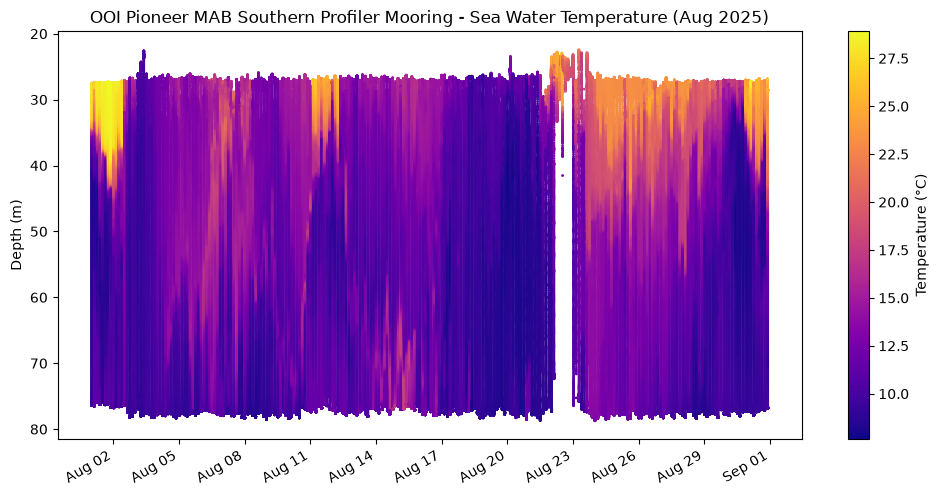

In [14]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 6))
cm = ax.scatter(ds_ooi_aug2025['time'], ds_ooi_aug2025['depth'], c=ds_ooi_aug2025['sea_water_temperature'], s=1, cmap='plasma')
ax.invert_yaxis()
ax.set_ylabel('Depth (m)')
ax.set_title('OOI Pioneer MAB Southern Profiler Mooring - Sea Water Temperature (Aug 2025)')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
fig.autofmt_xdate()
fig.colorbar(cm, ax=ax, label='Temperature (°C)')
plt.show()

There's a lot going on this month.  We see what might be a Gulf Stream intrusion at the start of the month, and then clearly something happened that affected the operation of the profiler around August 23, after which the surface layer was quite a bit warmer.  Even the lower layers were warmer.  Hurricanes are often known for cooling the ocean, so something different clearly happened here.  Likely warmer waters from offshore were advected in.  To verify that, we could look at satellite or model data. 

## Part B - ROMS Model Data
For the second part of this study, we will access ROMS Doppio model data from the Rutgers THREDDS data server. A few different products are available, but we will start with the hourly hindcast/forecast data available from the [ROMS doppio Real-Time Operational PSAS Forecast System Version 1 2017-present](https://tds.marine.rutgers.edu/thredds/catalog/roms/doppio/2017_da/avg/catalog.html?dataset=roms/doppio/2017_da/avg/Averages_Best_Excluding_Day1).

Because this model dataset is extremely large, this notebook will carefully subset the data to a single grid point and a specific time period before requesting the actual data.

### Step 1 - Discover - Find relevant ROMS Model data

ROMS Doppio model output is published on the Rutgers THREDDS server, which lets us browse available datasets and open them with `xarray` via OPeNDAP before deciding what (if anything) to download. Here we already know the dataset we want, so we connect directly to its `History_Best` aggregation.

In [15]:
doppio_url = 'https://tds.marine.rutgers.edu/thredds/dodsC/roms/doppio/2017_da/his/History_Best'
ds_roms = xr.open_dataset(doppio_url)
ds_roms

<xarray.Dataset> Size: 7TB
Dimensions:         (time: 78012, time1: 78012, time2: 480, time3: 78012,
                     tracer: 2, boundary: 4, s_rho: 40, s_w: 41, eta_rho: 106,
                     xi_rho: 242, eta_u: 106, xi_u: 241, eta_v: 105, xi_v: 242,
                     eta_psi: 105, xi_psi: 241, ocean_time: 24)
Coordinates: (12/18)
  * time            (time) datetime64[ns] 624kB 2017-11-02T01:00:00 ... 2026-...
    time_run        (time) datetime64[ns] 624kB ...
  * time1           (time1) datetime64[ns] 624kB 2017-11-02T01:00:00 ... 2026...
    time1_run       (time1) datetime64[ns] 624kB ...
  * time2           (time2) datetime64[ns] 4kB 2023-06-30T01:00:00 ... 2024-1...
  * time3           (time3) datetime64[ns] 624kB 2017-11-02T01:00:00 ... 2026...
    ...              ...
    lat_u           (eta_u, xi_u) float64 204kB ...
    lon_v           (eta_v, xi_v) float64 203kB ...
    lat_v           (eta_v, xi_v) float64 203kB ...
    lon_psi         (eta_psi, xi_psi) float64 202kB ...
    lat_psi         (eta_psi, xi_psi) float64 202kB ...
  * ocean_time      (ocean_time) datetime64[ns] 192B 2026-09-07T01:00:00 ... ...
Dimensions without coordinates: tracer, boundary, eta_rho, xi_rho, eta_u, xi_u,
                                eta_v, xi_v, eta_psi, xi_psi
Data variables: (12/123)
    time_offset     (time) datetime64[ns] 624kB ...
    time1_offset    (time1) datetime64[ns] 624kB ...
    time2_run       (time2) datetime64[ns] 4kB ...
    time2_offset    (time2) datetime64[ns] 4kB ...
    time3_offset    (time3) datetime64[ns] 624kB ...
    ntimes          int32 4B ...
    ...              ...
    sustr           (time1, eta_u, xi_u) float64 16GB ...
    svstr           (time1, eta_v, xi_v) float64 16GB ...
    v_northward_1m  (time, eta_rho, xi_rho) float64 16GB ...
    u_eastward_1m   (time, eta_rho, xi_rho) float64 16GB ...
    Vwind           (time, eta_rho, xi_rho) float64 16GB ...
    Uwind           (time, eta_rho, xi_rho) float64 16GB ...
Attributes: (12/49)
    file:                            doppio_his_7553_0002.nc
    format:                          netCDF-4/HDF5 file
    Conventions:                     CF-1.4, SGRID-0.3
    type:                            ROMS/TOMS history file
    title:                           ROMS doppio Real-Time Operational PSAS F...
    var_info:                        ../Data/varinfo1040t_daily.dat
    ...                              ...
    cdm_data_type:                   GRID
    featureType:                     GRID
    location:                        Proto fmrc:doppio_2017_da_his
    summary:                         doppio
    DODS_EXTRA.Unlimited_Dimension:  ocean_time
    EXTRA_DIMENSION.N:               40

In [16]:
print('\nDataset summary')
print(f'  Size:    {ds_roms.nbytes/1e12:,.3f} TB')

print('Temperature summary')
temp_var = ds_roms['temp']
print(f'  dims:        {temp_var.dims}')
print(f'  shape:       {temp_var.shape}')
print(f'  dtype:       {temp_var.dtype}')
print(f'  n_values:    {temp_var.size:,}')
print(f'  size:        {temp_var.nbytes/1e9:,.1f} GB')
print(f'  attrs:       {temp_var.attrs}')



Dataset summary
  Size:    6.746 TB
Temperature summary
  dims:        ('time', 's_rho', 'eta_rho', 'xi_rho')
  shape:       (78012, 40, 106, 242)
  dtype:       float64
  n_values:    80,046,552,960
  size:        640.4 GB
  attrs:       {'units': 'Celsius', 'long_name': 'potential temperature', 'time': 'ocean_time', 'grid': 'grid', 'location': 'face', 'field': 'temperature, scalar, series', '_ChunkSizes': array([  1,  20,  53, 121], dtype=int32), 'standard_name': 'sea_water_potential_temperature'}


The ROMS dataset is very large. Loading a full variable can take a very long time or fail because doing so will run into memory or server limits. So, we need to select only the relevant time range, horizontal grid point, and variables before calling `.load()`.  

If we were to make multiple requests to the same dataset, we should also download a local version to save on network and data server processing time.

#### Find the closest grid point to the Mooring
In order to extract the model data at the grid point we need, we need to know the location of the OOI Profiler.  Luckily, the latitude and longitude are included in the dataset. We will use their mean values to represent the mooring location.  (In this case, there is only one value anyway, but some moorings do move around a bit between deployments.)

In [17]:
ooi_lat = float(ds_ooi_aug2025['lat'].mean())
ooi_lon = float(ds_ooi_aug2025['lon'].mean())
print(f'OOI location: lat={ooi_lat:.4f}, lon={ooi_lon:.4f}')

OOI location: lat=35.7270, lon=-74.8564


In [18]:
def find_nearest_grid_point(lon2d, lat2d, target_lon, target_lat):
    """Return eta/xi indices of the ROMS rho-grid point closest to a target lon/lat."""
    dist2 = (lon2d - target_lon) ** 2 + (lat2d - target_lat) ** 2
    eta_idx, xi_idx = np.unravel_index(np.nanargmin(dist2.values), dist2.shape)
    return int(eta_idx), int(xi_idx)

def haversine_km(lon1, lat1, lon2, lat2):
    """Great-circle distance (km) between two lon/lat points, without an extra geo library."""
    r_earth = 6371.0
    lon1, lat1, lon2, lat2 = np.radians([lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return r_earth * 2 * np.arcsin(np.sqrt(a))

def describe_grid_point(eta_idx, xi_idx, label):
    """Look up lat/lon, bathymetric depth, land/sea mask, and distance to the OOI mooring for a grid point."""
    grid_lat = float(lat2d.isel(eta_rho=eta_idx, xi_rho=xi_idx).values)
    grid_lon = float(lon2d.isel(eta_rho=eta_idx, xi_rho=xi_idx).values)
    depth_m = float(ds_roms['h'].isel(eta_rho=eta_idx, xi_rho=xi_idx).values)
    mask = int(ds_roms['mask_rho'].isel(eta_rho=eta_idx, xi_rho=xi_idx).values)
    distance_km = haversine_km(ooi_lon, ooi_lat, grid_lon, grid_lat)
    print(f'{label}: eta={eta_idx}, xi={xi_idx}, lat/lon={grid_lat:.4f}, {grid_lon:.4f}')
    print(f'  Bathymetric depth: {depth_m:.2f} m (1=ocean, 0=land: {mask})')
    print(f'  Distance to OOI mooring: {distance_km:.2f} km')
    return {'eta_idx': eta_idx, 'xi_idx': xi_idx, 'lat': grid_lat, 'lon': grid_lon, 'depth_m': depth_m, 'mask': mask, 'distance_km': distance_km}

In [19]:
# Find the nearest ROMS grid point to the OOI Profiler
lon2d = ds_roms['lon_rho']
lat2d = ds_roms['lat_rho']

nearest_eta_idx, nearest_xi_idx = find_nearest_grid_point(lon2d, lat2d, ooi_lon, ooi_lat)
nearest_point = describe_grid_point(nearest_eta_idx, nearest_xi_idx, 'Nearest grid point')

Nearest grid point: eta=40, xi=39, lat/lon=35.7549, -74.8498
  Bathymetric depth: 336.64 m (1=ocean, 0=land: 1)
  Distance to OOI mooring: 3.16 km


After inspecting the bathymetry along this xi line (see plot below), a shallower point closer to the mooring's ~100 m depth is a better match than the geographically nearest point.

In [20]:
# Select a specific grid point
selected_eta_idx = 41
selected_point = describe_grid_point(selected_eta_idx, nearest_point['xi_idx'], 'Selected grid point')

# Specify the selected grid point indices and coordinates
eta_idx, xi_idx = selected_point['eta_idx'], selected_point['xi_idx']
grid_lat, grid_lon = selected_point['lat'], selected_point['lon']

Selected grid point: eta=41, xi=39, lat/lon=35.8034, -74.8995
  Bathymetric depth: 159.71 m (1=ocean, 0=land: 1)
  Distance to OOI mooring: 9.35 km


#### Inspect Nearby Points on the Same Xi Line

The geographically nearest ROMS rho point is not necessarily the best comparison point. The OOI site is approximately 100 meters deep, so inspect neighboring `eta` points along the selected `xi` column before choosing a model profile. This reveals whether the model bathymetry changes rapidly near the shelf break.

In [23]:
# Inspect a window of neighboring eta points on the selected xi column.
xi_line = pd.DataFrame({
    'eta': np.arange(lat2d.shape[0]),
    'latitude': lat2d.isel(xi_rho=xi_idx).values,
    'longitude': lon2d.isel(xi_rho=xi_idx).values,
    'depth_m': ds_roms['h'].isel(xi_rho=xi_idx).values,
    'ocean': ds_roms['mask_rho'].isel(xi_rho=xi_idx).values.astype(bool),
})

eta_window = 10
eta_focus = sorted({nearest_point['eta_idx'], selected_point['eta_idx']})
eta_start = max(0, eta_focus[0] - eta_window)
eta_end = min(lat2d.shape[0], eta_focus[-1] + eta_window + 1)
xi_line_nearby = xi_line.iloc[eta_start:eta_end].copy()

display(xi_line_nearby)

,eta,latitude,longitude,depth_m,ocean
30,30,35.268427,-74.356779,2837.304205,True
31,31,35.317164,-74.405819,2712.723135,True
32,32,35.365881,-74.454919,2576.653022,True
33,33,35.414579,-74.504078,2433.004272,True
34,34,35.463257,-74.553295,2277.099213,True
35,35,35.511914,-74.602572,2084.910954,True
36,36,35.560551,-74.651908,1864.058402,True
37,37,35.609169,-74.701304,1600.202861,True
38,38,35.657765,-74.750759,966.057506,True
39,39,35.706342,-74.800274,518.467102,True


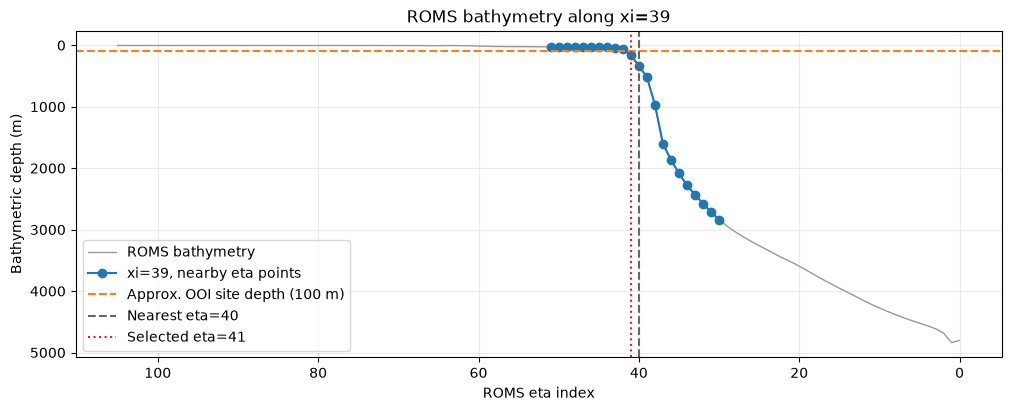

In [24]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(xi_line['eta'], xi_line['depth_m'], color='0.6', lw=1, label='ROMS bathymetry')
ax.plot(
    xi_line_nearby['eta'],
    xi_line_nearby['depth_m'],
    'o-',
    color='tab:blue',
    label=f'xi={xi_idx}, nearby eta points',
)
ax.axhline(100, color='tab:orange', ls='--', label='Approx. OOI site depth (100 m)')
ax.axvline(nearest_point['eta_idx'], color='0.4', ls='--', label=f'Nearest eta={nearest_point["eta_idx"]}')
ax.axvline(selected_point['eta_idx'], color='tab:red', ls=':', label=f'Selected eta={selected_point["eta_idx"]}')

ax.invert_xaxis() # flip the xaxis
ax.set_xlabel('ROMS eta index')
ax.set_ylabel('Bathymetric depth (m)')
ax.set_title(f'ROMS bathymetry along xi={xi_idx}')
ax.invert_yaxis()
ax.legend()

ax.grid(True, alpha=0.25)
plt.show()

#### ROMS Domain Map
Now let's create a nice map of the full ROMS domain, with our selected station highlighted.

**Try it yourself:** change `selected_eta_idx` above and re-run to see how a different grid point (and its distance/depth mismatch with the mooring) affects the comparison later in this notebook.

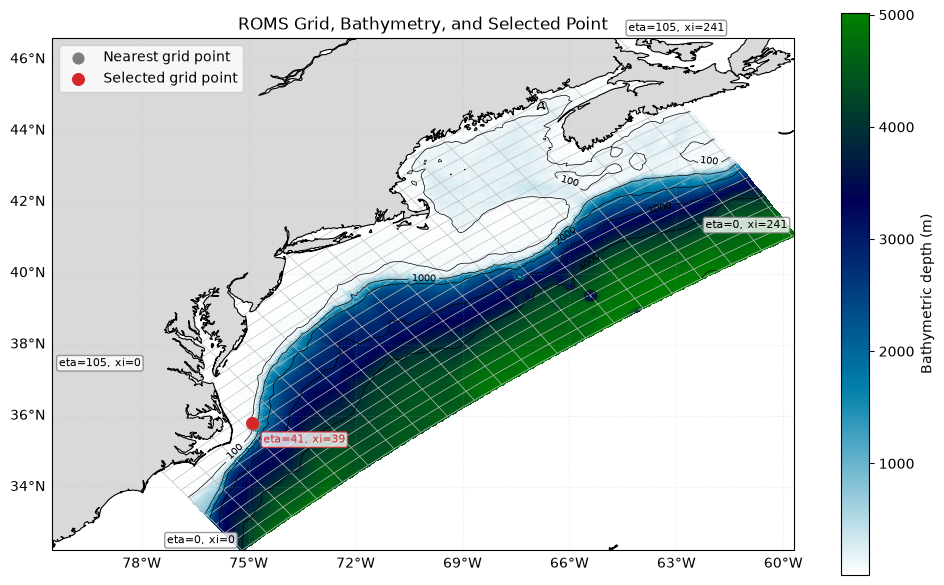

In [25]:
# ROMS domain map with coastlines and the selected point.
map_crs = ccrs.PlateCarree()
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={'projection': map_crs})

# Subsample grid lines to keep plotting light and readable.
step_eta = max(1, lat2d.shape[0] // 20)
step_xi = max(1, lat2d.shape[1] // 20)

for eta in range(0, lat2d.shape[0], step_eta):
    ax.plot(
        lon2d.isel(eta_rho=eta),
        lat2d.isel(eta_rho=eta),
        color='0.75',
        lw=0.5,
        transform=map_crs,
    )
for xi in range(0, lon2d.shape[1], step_xi):
    ax.plot(
        lon2d.isel(xi_rho=xi),
        lat2d.isel(xi_rho=xi),
        color='0.75',
        lw=0.5,
        transform=map_crs,
    )

bathymetry = ds_roms.h.plot.pcolormesh(
    x='lon_rho',
    y='lat_rho',
    cmap='ocean_r',
    ax=ax,
    transform=map_crs,
    add_colorbar=False,
)
contours = ds_roms.h.plot.contour(
    x='lon_rho',
    y='lat_rho',
    colors='k',
    levels=[100, 1000, 2000, 3000, 4000, 5000],
    linewidths=0.5,
    ax=ax,
    transform=map_crs,
    add_colorbar=False,
)
contours.clabel(fmt='%d', fontsize=7, colors='k', inline=True, inline_spacing=4)

ax.add_feature(cfeature.LAND, facecolor='0.85', edgecolor='none', zorder=2)
ax.coastlines(resolution='10m', color='black', linewidth=0.8, zorder=3)

ax.scatter(
    nearest_point['lon'],
    nearest_point['lat'],
    s=60,
    c='tab:gray',
    marker='o',
    label='Nearest grid point',
    zorder=4,
    transform=map_crs,
)
ax.scatter(
    selected_point['lon'],
    selected_point['lat'],
    s=70,
    c='tab:red',
    marker='o',
    label='Selected grid point',
    zorder=4,
    transform=map_crs,
)

# Label the four grid corners and the selected grid point.
corner_indices = [
    (0, 0),
    (0, lon2d.shape[1] - 1),
    (lat2d.shape[0] - 1, 0),
    (lat2d.shape[0] - 1, lon2d.shape[1] - 1),
]
for corner_eta, corner_xi in corner_indices:
    corner_lon = float(lon2d.isel(eta_rho=corner_eta, xi_rho=corner_xi).values)
    corner_lat = float(lat2d.isel(eta_rho=corner_eta, xi_rho=corner_xi).values)
    is_top_corner = corner_eta == 0
    ax.annotate(
        f'eta={corner_eta}, xi={corner_xi}',
        xy=(corner_lon, corner_lat),
        xytext=(-5 if is_top_corner else 5, 5),
        textcoords='offset points',
        fontsize=8,
        ha='right' if is_top_corner else 'left',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.8, ec='0.5'),
        zorder=5,
        xycoords=map_crs._as_mpl_transform(ax),
    )

ax.annotate(
    f'eta={eta_idx}, xi={xi_idx}',
    xy=(grid_lon, grid_lat),
    xytext=(8, -14),
    textcoords='offset points',
    fontsize=8,
    color='tab:red',
    bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.8, ec='tab:red'),
    zorder=5,
    xycoords=map_crs._as_mpl_transform(ax),
)

ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('ROMS Grid, Bathymetry, and Selected Point')
ax.legend(loc='best')
gridlines = ax.gridlines(draw_labels=True, alpha=0.25, linestyle=':')
gridlines.top_labels = False
gridlines.right_labels = False
ax.set_extent([
    float(lon2d.min()),
    float(lon2d.max()),
    float(lat2d.min()),
    float(lat2d.max()),
], crs=map_crs)
fig.colorbar(bathymetry, ax=ax, label='Bathymetric depth (m)')
plt.tight_layout()
plt.show()

### Step 2 - Access (Parse and Load)
Next we can load the ROMS profile timeseries data we are interested in.


For this example we will load only the August 2025 temperature and salinity profiles at the selected grid point.  We will call `.load()` now which will actually load the dataset into memory.  Because it takes a while for THREDDS to extract this dataset, this line will take a while.  Because THREDDS caches previous requests, this line may actually run faster if you run it again.

In [26]:
%%time
# Load Selected ROMS Profiles
ds_profile_temp = ds_roms['temp'].sel(time=slice('2025-08-01', '2025-09-01'), eta_rho=eta_idx, xi_rho=xi_idx).load()
ds_profile_sal = ds_roms['salt'].sel(time=slice('2025-08-01', '2025-09-01'), eta_rho=eta_idx, xi_rho=xi_idx).load()

CPU times: user 20.8 ms, sys: 4.41 ms, total: 25.3 ms
Wall time: 16.2 s


In [27]:
print(f'Temp dataset size:        {ds_profile_temp.nbytes/1e6:,.1f} MB')

Temp dataset size:        0.2 MB


### Step 3 - Wrangle (restructure, clean, merge, and quality control)


The only thing we have to do for this dataset is convert the ROMS s-coordinate to a usable depth.  (If we were to use a library like `xroms` it would handle this for us.)

ROMS `s_rho` is a dimensionless vertical coordinate with values from approximately -1 at the bottom to 0 at the surface. ROMS physical depth also depends on bathymetry, sea-surface height, stretching parameters, and `Vtransform`, so it must be calculated rather than estimated as `s_rho * h`.

ROMS supports two `Vtransform` conventions for combining these terms: `Vtransform=1` ([Song and Haidvogel, 1994](https://doi.org/10.1006/jcph.1994.1088)) computes a resting-depth-referenced `z0` and then stretches it for the free surface, while `Vtransform=2` ([Shchepetkin and McWilliams, 2005](https://doi.org/10.1016/j.ocemod.2004.08.002)) computes a fractional depth between 0 and 1 and scales the full water column (`h + zeta`) by it. The Doppio dataset reports which convention it uses via the `Vtransform` variable, so the code below branches on that value rather than assuming one formula.

The conversion combines four pieces at our selected grid point:

- `h`: the time-invariant bathymetric (resting) depth
- `Cs_r`: the stretching-curve values that shape how sigma levels bunch up near the surface or the seafloor
- `zeta`: the sea-surface height anomaly, which raises/lowers every sigma level as it changes in time
- `hc`: a critical depth parameter that controls how sigma levels are distributed between shallow and deep water

In [28]:
# Same point and time range as ds_profile_temp
zeta_pt = ds_roms["zeta"].sel(
    time=slice('2025-08-01', '2025-09-01'),
    eta_rho=eta_idx,
    xi_rho=xi_idx,
)

h_pt = ds_roms["h"].isel(eta_rho=eta_idx, xi_rho=xi_idx)
hc = ds_roms["hc"]
s_rho = ds_roms["s_rho"]
Cs_r = ds_roms["Cs_r"]
Vtransform = int(ds_roms["Vtransform"])

if Vtransform == 1:
    z0 = hc * (s_rho - Cs_r) + h_pt * Cs_r
    z_rho = z0 + zeta_pt * (1 + z0 / h_pt)
elif Vtransform == 2:
    z0 = (hc * s_rho + h_pt * Cs_r) / (hc + h_pt)
    z_rho = zeta_pt + (zeta_pt + h_pt) * z0
else:
    raise ValueError(f"Unsupported Vtransform: {Vtransform}")

# Store depth as positive meters downward for direct comparison with OOI.
ds_profile_temp = ds_profile_temp.assign_coords(depth=(-z_rho).transpose("time", "s_rho"))
ds_profile_sal = ds_profile_sal.assign_coords(depth=(-z_rho).transpose("time", "s_rho"))

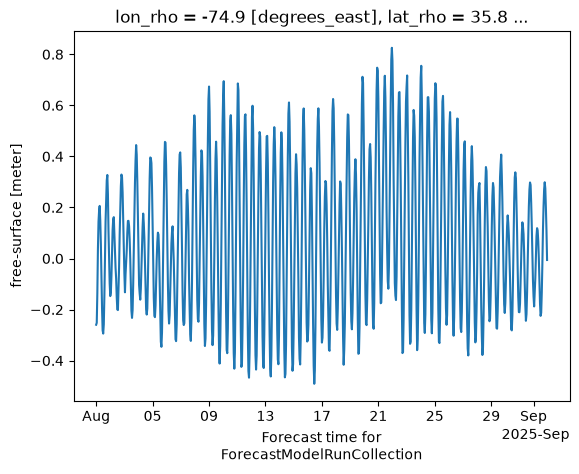

In [29]:
# Quickplot of the Zeta variable
zeta_pt.plot()

### Step 4 - Reuse - Visualization and Analysis

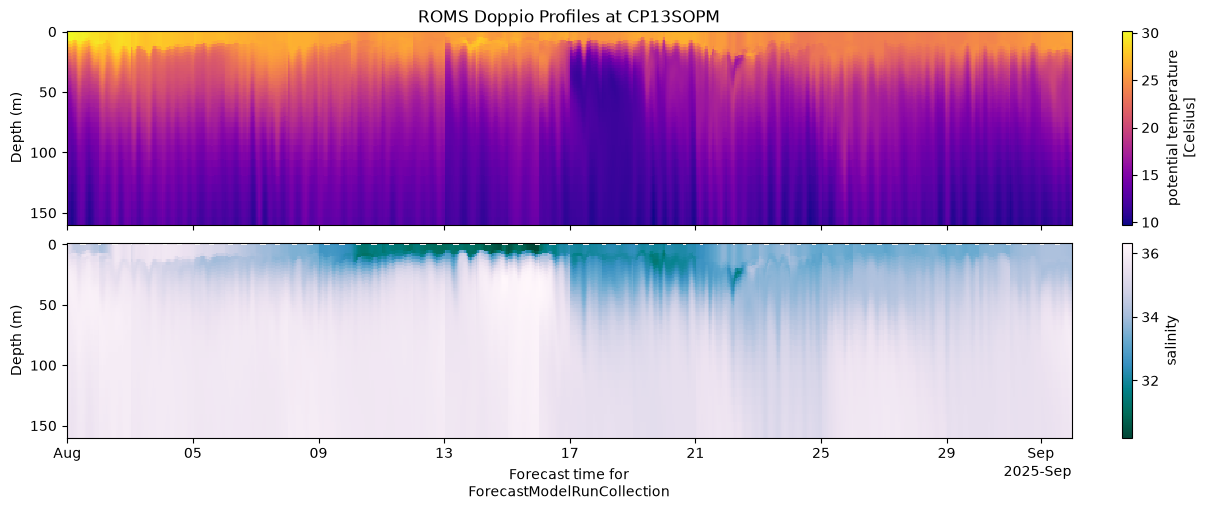

In [30]:
# Quickplot the ROMS profiles 
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, sharey=True, constrained_layout=True)

# We could use either depth or s_rho coordinates for the y-axis
ds_profile_temp.plot(
    x='time', y='depth', 
    yincrease=False, ax=axes[0], cmap='plasma', 
    vmin=float(ds_profile_temp.min()), vmax=float(ds_profile_temp.max()))
ds_profile_sal.plot(
    x='time', y='depth', 
    yincrease=False, ax=axes[1], cmap='PuBuGn_r', 
    vmin=float(ds_profile_sal.min()), vmax=float(ds_profile_sal.max()))

# axes[0].invert_yaxis()
# axes[0].set_ylim([80,0])  # Focus on upper 80 m to better compare with OOI profiler data

axes[0].set_xlabel('')
axes[1].set_title('')
axes[0].set_ylabel("Depth (m)")
axes[1].set_ylabel("Depth (m)")
axes[0].set_title('ROMS Doppio Profiles at CP13SOPM');

## Combined OOI Profiler and ROMS Plot

The ROMS panels show model values on sigma levels converted to time-varying physical depths using bathymetry, sea-surface height, and the ROMS vertical-coordinate parameters.

To plot the OOI panels the same way (with `pcolormesh`), the profiler observations need to be on a regular profile x depth grid too. Because of the data gaps between casts, that takes a bit more than a plain `groupby_bins` call: we first have to split the record into individual profiles using the time gaps, then bin each profile by depth.


In [34]:
def build_profile_grid_xr(ds, value_var, depth_var='depth', profile_gap=np.timedelta64(30, 'm'), depth_bin=1.0):
    """Bin an xarray profiler timeseries into a profile x depth-bin DataArray, splitting casts on time gaps."""
    ds = ds[[value_var, depth_var]]

    # Time gaps larger than profile_gap mark the start of a new cast
    is_new_profile = np.diff(ds['time'].values) > profile_gap
    profile_id = np.concatenate([[0], np.cumsum(is_new_profile)])
    ds = ds.assign_coords(profile_id=('time', profile_id))

    depth_edges = np.arange(0, float(ds[depth_var].max()) + depth_bin, depth_bin)
    binned = ds.groupby('profile_id').map(lambda d: d.groupby_bins(depth_var, depth_edges).mean())

    profile_time = ds['time'].groupby('profile_id').min()
    binned = binned.assign_coords(profile_time=('profile_id', profile_time.values))
    binned = binned.swap_dims({'profile_id': 'profile_time'}).sortby('profile_time')

    depth_bin_centers = [interval.mid for interval in binned[f'{depth_var}_bins'].values]
    return binned[value_var].assign_coords({f'{depth_var}_bins': depth_bin_centers})

# groupby/groupby_bins need the data in memory, not dask-backed
ooi_aug2025_loaded = ds_ooi_aug2025[['sea_water_temperature', 'sea_water_practical_salinity', 'depth']].compute()

temp_grid_da = build_profile_grid_xr(ooi_aug2025_loaded, 'sea_water_temperature')
sal_grid_da = build_profile_grid_xr(ooi_aug2025_loaded, 'sea_water_practical_salinity')

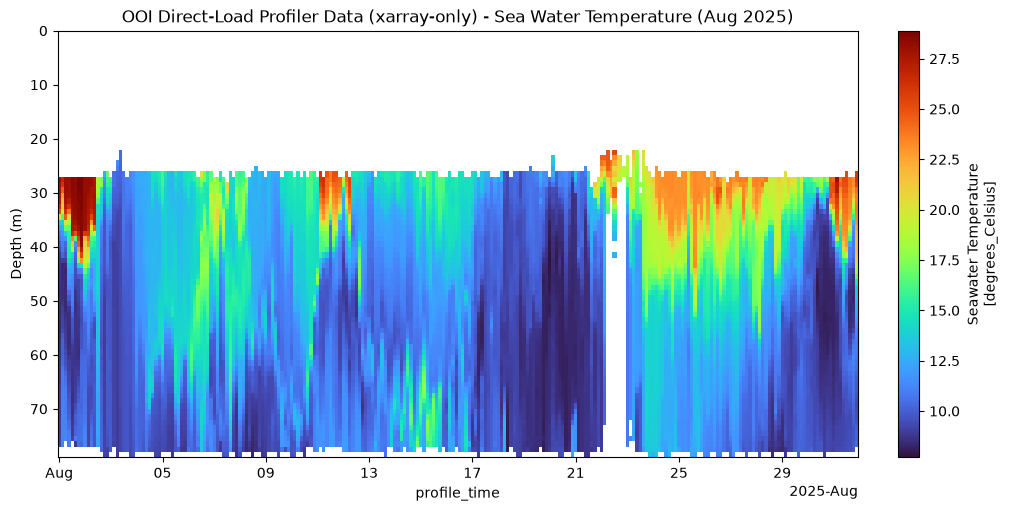

In [35]:
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
temp_grid_da.plot.pcolormesh(x='profile_time', y='depth_bins', cmap='turbo', ax=ax)
ax.invert_yaxis()
ax.set_ylabel('Depth (m)')
ax.set_title('OOI Direct-Load Profiler Data (xarray-only) - Sea Water Temperature (Aug 2025)')
plt.show()

In [36]:
# Calculate variable and time limits
temp_min = min(float(ds_ooi_aug2025['sea_water_temperature'].min(skipna=True)), float(ds_profile_temp.min(skipna=True)))
temp_max = max(float(ds_ooi_aug2025['sea_water_temperature'].max(skipna=True)), float(ds_profile_temp.max(skipna=True)))
sal_min = min(float(ds_ooi_aug2025['sea_water_practical_salinity'].min(skipna=True)), float(ds_profile_sal.min(skipna=True)))
sal_max = max(float(ds_ooi_aug2025['sea_water_practical_salinity'].max(skipna=True)), float(ds_profile_sal.max(skipna=True)))
start_time = ds_ooi_aug2025['time'].min().values
end_time = ds_ooi_aug2025['time'].max().values

Finally, let's make a combined plot comapring the 2 datasets for both temperature and salinity.

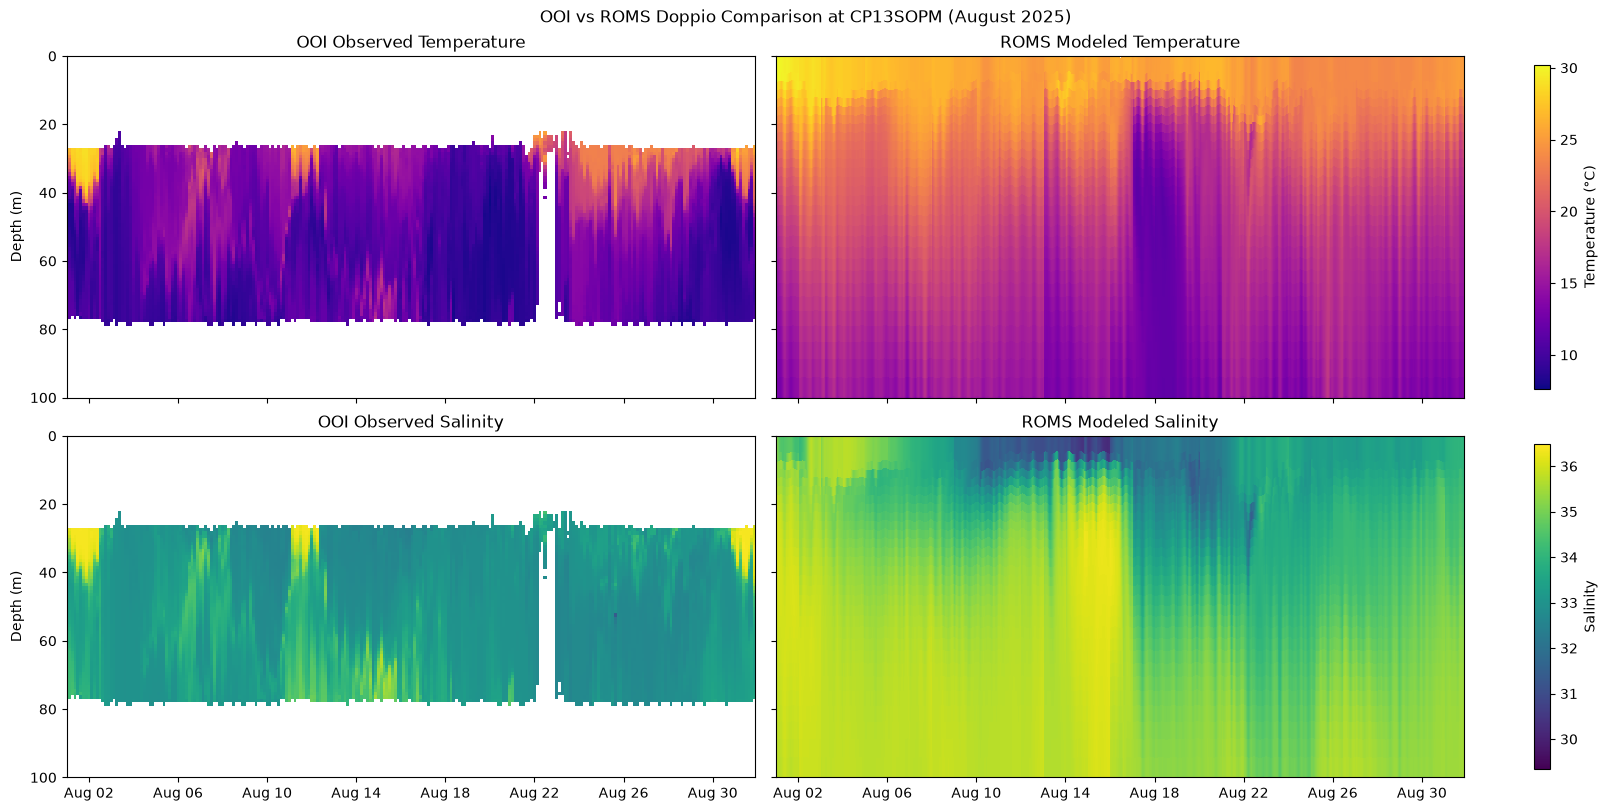

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey=True, constrained_layout=True)

cm_temp = temp_grid_da.plot.pcolormesh(x='profile_time', y='depth_bins', ax=axes[0, 0], add_colorbar=False, cmap='plasma', vmin=temp_min, vmax=temp_max)
cm_sal = sal_grid_da.plot.pcolormesh(x='profile_time', y='depth_bins', ax=axes[1, 0], add_colorbar=False, cmap='viridis', vmin=sal_min, vmax=sal_max)

ds_profile_temp.plot(x='time', y='depth', ax=axes[0, 1], add_colorbar=False, cmap='plasma', vmin=temp_min, vmax=temp_max)
ds_profile_sal.plot(x='time', y='depth', ax=axes[1, 1], add_colorbar=False, cmap='viridis', vmin=sal_min, vmax=sal_max)

axes[0,0].invert_yaxis()
axes[0,0].set_ylim(100,0)
axes[0,0].set_xlim(pd.Timestamp(start_time), pd.Timestamp(end_time))

for ax in axes.flat:
    ax.set_title('')  # clear any auto-generated xarray coordinate title
    ax.set_xlabel('')

for ax in axes[1, :]:
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

fig.suptitle('OOI vs ROMS Doppio Comparison at CP13SOPM (August 2025)')
axes[0, 0].set_title('OOI Observed Temperature')
axes[0, 1].set_title('ROMS Modeled Temperature')
axes[1, 0].set_title('OOI Observed Salinity')
axes[1, 1].set_title('ROMS Modeled Salinity')
axes[0, 0].set_ylabel('Depth (m)')
axes[1, 0].set_ylabel('Depth (m)')
axes[0, 1].set_ylabel('')  # shares y-axis with the left column
axes[1, 1].set_ylabel('')  # shares y-axis with the left column

fig.colorbar(cm_temp, ax=axes[0, :], label='Temperature (°C)', shrink=0.95)
fig.colorbar(cm_sal, ax=axes[1, :], label='Salinity', shrink=0.95)
plt.show()

While these are comparable time-depth views, it's important to remember that these two datasets are two very different representations of the ocean.

## Summary
Here are a few takeaways from the notebook.

### Data Access
* In this notebook we were easily able to download a month of ROMS data to compare with an OOI profiler.
* However, accessing longer timeframes over THREDDS would be more challenging, requiring different strategies.
* Comparing point observations to a regional ocean model can be tricky, as the depth of the "nearest grid point" may change rapidly over just a few grid cells, especially near a shelf break. In this case, the nearest model point is in roughly 300m of water, while the profiler is closer to 100m. In this case, it was helpful to review the bathymetry along the `xi` line in order to pick a point closer to the actual deployment depth of the mooring.
* This particular dataset does not have a true "depth" variable, so we need to convert `s_rho` levels to physical depth.  (Some model libraries, like xroms may do this automatically.) 

### Oceanographic Notes
* Over this time period, the model tends to run warmer than the observed profiler temperatures at the surface and mid depths.  Of course, the profiler is missing much of the surface layer, since it measures the portion of the water column from 30-70m.  In addition, the model depth at this location is about 140m, so comparisons are not straightforward.
* Below the surface, the model also appears to be a lot saltier than the observations, especially for the first half of the month.
* A few features appear to line up between the datasets, including what looks like a warm-core eddy or intrusion early in the month and again around the 12th and the 30th, though the signal is weaker and less sharply defined in the model. 
* It's not fully clear why the disagreement is otherwise so persistent, but a few plausible contributors:
  * The shelf-break region here is dynamically active (we're at the shelfbreak front, where Gulf Stream eddies and cross-shelf exchange processes vary a lot, and even a several-kilometer model grid may not resolve the frontal-scale structure the profiler is sampling.
  * Data assimilation and initialization in the ROMS Doppio hindcast could shift the timing or strength of features without necessarily affecting larger scale patterns.  In this case, we can see the eddy signal in both the model and observations, but it is not as strong, nor is the mixed-layer depth as pronounced.  Models still have trouble resolving fine features like this.